# **M6 DINO Attention heads**
The aim of this notebook is to visualize how any patch of our choice attends to the other patches in the image.



## **1. Transformer**
Transformer is a deep learning model architecture that relies on self-attention mechanisms to process sequential data. It was introduced in the paper "Attention is All You Need" by Vaswani et al. in 2017.
The key components of the Transformer architecture include:
- Multi-head Self-Attention: This mechanism allows the model to focus on different parts of the input sequence simultaneously, capturing various relationships and dependencies.
- Feedforward Neural Networks: These are fully connected layers that process the output of the attention mechanism, adding non-linearity to the model.
- Positional Encoding: Since Transformers do not have a built-in notion of sequence order, positional encodings are added to the input embeddings to provide information about the position of each token in the sequence.
- Layer Normalization and Residual Connections: These techniques help stabilize training and improve convergence by normalizing the inputs to each layer and allowing gradients to flow more easily through the network.
- Stacked Layers: Transformers consist of multiple layers of attention and feedforward networks, allowing the model to learn complex representations of the input data.

Tunable parameters in a Transformer model include:
- $W_q$ - Weight matrix for Query
- $W_k$ - Weight matrix for Key
- $W_v$ - Weight matrix for Value
- Number of attention heads

<div style="text-align: center;">
<img src="https://m.media-amazon.com/images/S/pv-target-images/57c889a8cda5e755e1ef0a4e47268fbf7af5e37c39972ff5b8372588289d4cd7.jpg" width="800" alt="transformer">
</div>


### **1.1 Attention Head**

An attention head is the fundamental component of the "Scaled Dot-Product Attention" mechanism, which is the core of Multi-Head Attention used in Transformers. Its purpose is to compute a **weighted sum of value vectors**, where the weights are determined by the **similarity between query and key vectors**.

It takes an input sequence (e.g., a set of token embeddings, $X$) and transforms it using three distinct, learnable weight matrices:

* **$W_q$ (Query Matrix):** This matrix is multiplied by the input $X$ to produce the **Query** vectors ($Q$).
* **$W_k$ (Key Matrix):** This matrix is multiplied by the input $X$ to produce the **Key** vectors ($K$).
* **$W_v$ (Value Matrix):** This matrix is multiplied by the input $X$ to produce the **Value** vectors ($V$).

These matrices are learned during the model's training process and are unique for each attention head.

### ⚙️ How it Multiplies (The Calculation)

The process involves several steps:

1.  **Projection:** The input $X$ (which has a dimension, let's say $d_{\text{model}}$) is projected into the $Q$, $K$, and $V$ spaces. The dimensions of these new vectors (let's call them $d_q$, $d_k$, $d_v$) are often smaller than $d_{\text{model}}$, especially in multi-head attention (where $d_q = d_k = d_v = d_{\text{model}} / \text{num\_heads}$).

    * $Q = X \cdot W_q$
    * $K = X \cdot W_k$
    * $V = X \cdot W_v$

    

2.  **Calculate Attention Scores:** The similarity between each Query vector and all Key vectors is calculated using a dot product. This results in a matrix of raw attention scores.

    * **Scores** = $Q \cdot K^T$ (where $K^T$ is the transpose of the Key matrix)

3.  **Scaling:** The scores are scaled down by dividing by the square root of the dimension of the key vectors ($d_k$). This step is crucial for stabilizing gradients during training, preventing the dot products from becoming too large.

    * **Scaled Scores** = $\frac{Q K^T}{\sqrt{d_k}}$

4.  **Softmax (Normalization):** A softmax function is applied along the key dimension (rows of the scaled score matrix). This converts the scores into positive values that sum to 1, effectively turning them into **attention weights** (probabilities). A high weight means the corresponding value is very important for the current query.

    * **Weights** = $\text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right)$

5.  **Compute Output:** Finally, the attention weights are multiplied by the Value vectors ($V$). This produces the output of the attention head—a new set of vectors where each vector is a weighted sum of all the Value vectors.

    * **Output (Z)** = $\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}}\right) V$

The resulting matrix $Z$ has the same dimensions as $V$ and represents the input sequence with attention applied. Each token's new representation is now a mix of other tokens' values, based on how "relevant" they were deemed by the query-key similarity.
<div style="text-align: center;">
<img src="https://i.ytimg.com/vi/mMa2PmYJlCo/maxresdefault.jpg" width="800" alt="multihead attention">
</div>

## **2. Importing**

In [99]:
import torch
import numpy as np
import torchvision
from transformers import AutoImageProcessor, AutoModel
from torch.utils.data import DataLoader
import h5py
import random
import kagglehub
import os
from torchvision.datasets import ImageFolder
from torchvision import transforms
import matplotlib.pyplot as plt

In [100]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### **2.1 Hugging face**

In [101]:
from huggingface_hub import login
login()

In [102]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "facebook/dinov3-vits16-pretrain-lvd1689m"
HDF5_FILE = "dino_features.h5"
print(f"Loading model: {model_name}")

model = AutoModel.from_pretrained(model_name).to(device).eval()

Loading model: facebook/dinov3-vits16-pretrain-lvd1689m


## **3. Datasets**

In [103]:
processor = AutoImageProcessor.from_pretrained(model_name)
transform = lambda img: processor(images=img, return_tensors="pt")['pixel_values'].squeeze()

### **3.1 CIFAR-10 and CIFAR-100**


In [104]:
#CIFAR-10
dataset_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
loader_cifar10 = DataLoader(dataset_cifar10, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR10 samples (OOD - CIFAR-10): {len(dataset_cifar10)}")

Amount of CIFAR10 samples (OOD - CIFAR-10): 10000


In [105]:
#CIFAR-100
dataset_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
loader_cifar100 = DataLoader(dataset_cifar100, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of CIFAR100 samples (OOD - CIFAR-100): {len(dataset_cifar100)}")

Amount of CIFAR100 samples (OOD - CIFAR-100): 10000


### **3.2 SVHN**

In [106]:
dataset_svhn = torchvision.datasets.SVHN(root='./data', split='test', download=True, transform=transform)
loader_svhn = DataLoader(dataset_svhn, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of SVHN samples (Test set): {len(dataset_svhn)}")

Amount of SVHN samples (Test set): 26032


### **3.3 FOOD101**

In [107]:
dataset_food101 = torchvision.datasets.Food101(root='./data', split='test', download=True, transform=transform)
loader_food101 = DataLoader(dataset_food101, batch_size=64, shuffle=False, num_workers=2)
print(f"Amount of Food101 samples (test set): {len(dataset_food101)}")

Amount of Food101 samples (test set): 25250


### **3.4 Pokémon**

In [108]:
path = kagglehub.dataset_download("thedagger/pokemon-generation-one")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'pokemon-generation-one' dataset.
Path to dataset files: /kaggle/input/pokemon-generation-one


In [109]:
transform_kaggle = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5])
])

image_root_path = os.path.join(path, 'dataset')

dataset_pokemon_gen1 = ImageFolder(
    root=image_root_path,
    transform=transform_kaggle
)

loader_pokemon_gen1 = DataLoader(
    dataset_pokemon_gen1,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

print(f"\n✅ Success! Loaded {len(dataset_pokemon_gen1)} images.")
print(f"Found classes: {dataset_pokemon_gen1.classes[:5]}...")


✅ Success! Loaded 21314 images.
Found classes: ['Abra', 'Aerodactyl', 'Alakazam', 'Arbok', 'Arcanine']...


## **4. Getting attention maps**

### **4.1 Implementation**

- `.attentions` shape: `(batch_size, num_heads, num_tokens, num_tokens)`
  *   `batch_size`: Usually 1 for a single image
  *   `num_heads`: The number of attention heads in that layer
  *   `num_tokens`: The total number of patches plus the [CLS] token. For a 224x224 image with 16x16 patches, this would be (224/16)2+1=142+1=197.

### **4.2 Dictionary**
- `CLS` - The [CLS] token is a special, artificial token added to the beginning of an input sequence for Transformer models like BERT and Vision Transformers (ViT). Its name stands for "Classification", and its primary purpose is to act as a summary or aggregate representation for the entire input sequence. For Images (ViT): [CLS], [patch_1], [patch_2], [patch_3], ...

In [110]:
def get_attention_maps(image, model, processor, device):
  """
  Get attention maps for a given image using a pre-trained model.

  :param image: The input image.
  :param model: The pre-trained model.
  :param processor: The image processor.
  :param device: The device to use for computation (e.g., 'cuda' or 'cpu').

  :return: Full attention matrix between patches.
  """

  inputs = processor(images=image, return_tensors="pt")
  inputs = {k: v.to(device) for k, v in inputs.items()}

  model.set_attn_implementation('eager')

  with torch.no_grad():
      outputs = model(**inputs, output_attentions=True)

  # Get attention from last layer
  attentions = outputs.attentions[-1]  # Shape: [batch, num_heads, num_patches, num_patches]

  # Average across all attention heads
  attention = attentions[0].mean(dim=0)  # Shape: [num_patches, num_patches]

  # Return full attention matrix (excluding CLS token)
  return attention[1:, 1:]  # Remove CLS token from both dimensions


### **4.3 Computing the attention**

In [111]:
import random

**4.3.1 CIFAR-10 and CIFAR-100**

In [112]:
#CIFAR-10
cifar10_image, cifar10_label = dataset_cifar10[0]
attention_cifar10_image = get_attention_maps(cifar10_image, model, processor, device)

In [113]:
#CIFAR-100
cifar100_image, cifar100_label = dataset_cifar100[0]
attention_cifar100_image = get_attention_maps(cifar100_image, model, processor, device)

## **5. Visualization**


In [114]:
from PIL import Image

In [115]:
orig_cifar10 = torchvision.datasets.CIFAR10(root='./data', train=False, download=False, transform=None)
orig_cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=False, transform=None)
orig_svhn = torchvision.datasets.SVHN(root='./data', split='test', download=False, transform=None)
orig_food101 = torchvision.datasets.Food101(root='./data', split='test', download=False, transform=None)

In [116]:
transform_for_viz = transforms.Compose([
    transforms.Resize((64, 64)),
    # THIS IS THE KEY FIX:
    # Convert everything (including RGBA and Palette) to standard RGB
    transforms.Lambda(lambda img: img.convert('RGB')),
])

# 2. Load the dataset ONLY for visualization
orig_pokemon_gen1 = ImageFolder(
    root=image_root_path,
    transform=transform_for_viz
)

In [117]:
pokemon_class_names = orig_pokemon_gen1.classes

### **5.1 Implementation**

In [118]:
def visualize_attention_random(dataset, model, processor, device, class_names=None):
    idx = random.randint(0, len(dataset) - 1)
    image, label = dataset[idx]

    # Default class names for CIFAR-10 if not provided
    if class_names is None:
        class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                       'dog', 'frog', 'horse', 'ship', 'truck']

    attention_matrix = get_attention_maps(image, model, processor, device)

    if isinstance(image, torch.Tensor):
        original_image = image.clone()
        original_image = original_image.permute(1, 2, 0)
        original_image = (original_image - original_image.min()) / (original_image.max() - original_image.min())
        original_image = original_image.cpu().numpy()
    else:
        original_image = np.array(image)

    num_patches_total = attention_matrix.shape[0]
    h, w = original_image.shape[:2]

    valid_grids = []
    for hp in range(1, num_patches_total + 1):
        if num_patches_total % hp == 0:
            wp = num_patches_total // hp
            valid_grids.append((hp, wp))
    h_patches, w_patches = min(valid_grids, key=lambda x: abs(x[0] - x[1]))

    random_patch_idx = random.randint(0, num_patches_total - 1)
    patch_row = random_patch_idx // w_patches
    patch_col = random_patch_idx % w_patches

    attention_from_patch = attention_matrix[random_patch_idx, :].cpu().numpy()

    print(f"Image idx: {idx}, Grid: {h_patches}x{w_patches} = {h_patches * w_patches}, Total patches: {num_patches_total}")
    print(f"Label: {class_names[label]}")
    print(f"Selected patch: ({patch_row}, {patch_col}) [index: {random_patch_idx}]")
    print(f"Attention stats - min: {attention_from_patch.min():.4f}, max: {attention_from_patch.max():.4f}, mean: {attention_from_patch.mean():.4f}")

    attention_reshaped = attention_from_patch.reshape(h_patches, w_patches)

    # Print attention distribution to diagnose top-left corner issue
    print(f"Attention map corners:")
    print(f"  Top-left (0,0): {attention_reshaped[0, 0]:.4f}")
    print(f"  Top-right (0,-1): {attention_reshaped[0, -1]:.4f}")
    print(f"  Bottom-left (-1,0): {attention_reshaped[-1, 0]:.4f}")
    print(f"  Bottom-right (-1,-1): {attention_reshaped[-1, -1]:.4f}")

    attention_reshaped = (attention_reshaped - attention_reshaped.min()) / \
                         (attention_reshaped.max() - attention_reshaped.min())

    attention_upsampled = np.array(Image.fromarray((attention_reshaped * 255).astype(np.uint8)).resize((w, h), Image.BICUBIC))
    attention_upsampled = attention_upsampled / 255.0

    patch_h = h / h_patches
    patch_w = w / w_patches
    patch_y1 = int(patch_row * patch_h)
    patch_y2 = int((patch_row + 1) * patch_h)
    patch_x1 = int(patch_col * patch_w)
    patch_x2 = int((patch_col + 1) * patch_w)

    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Original image with red square on selected patch
    axes[0].imshow(original_image)
    rect = plt.Rectangle((patch_x1, patch_y1), patch_x2 - patch_x1, patch_y2 - patch_y1,
                         linewidth=2, edgecolor='red', facecolor='none')
    axes[0].add_patch(rect)
    axes[0].set_title(f"Original Image\n{class_names[label]}\nSelected Patch: ({patch_row}, {patch_col})")
    axes[0].axis("off")

    axes[1].imshow(attention_upsampled, cmap="jet")
    axes[1].set_title("Attention from Selected Patch")
    axes[1].axis("off")

    axes[2].imshow(original_image)
    axes[2].imshow(attention_upsampled, cmap="jet", alpha=0.6)
    rect2 = plt.Rectangle((patch_x1, patch_y1), patch_x2 - patch_x1, patch_y2 - patch_y1,
                          linewidth=2, edgecolor='red', facecolor='none')
    axes[2].add_patch(rect2)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

### **5.2 CIFAR-10 and CIFAR-100**

Image idx: 2417, Grid: 10x20 = 200, Total patches: 200
Label: horse
Selected patch: (2, 19) [index: 59]
Attention stats - min: 0.0009, max: 0.0353, mean: 0.0049
Attention map corners:
  Top-left (0,0): 0.0134
  Top-right (0,-1): 0.0035
  Bottom-left (-1,0): 0.0013
  Bottom-right (-1,-1): 0.0056


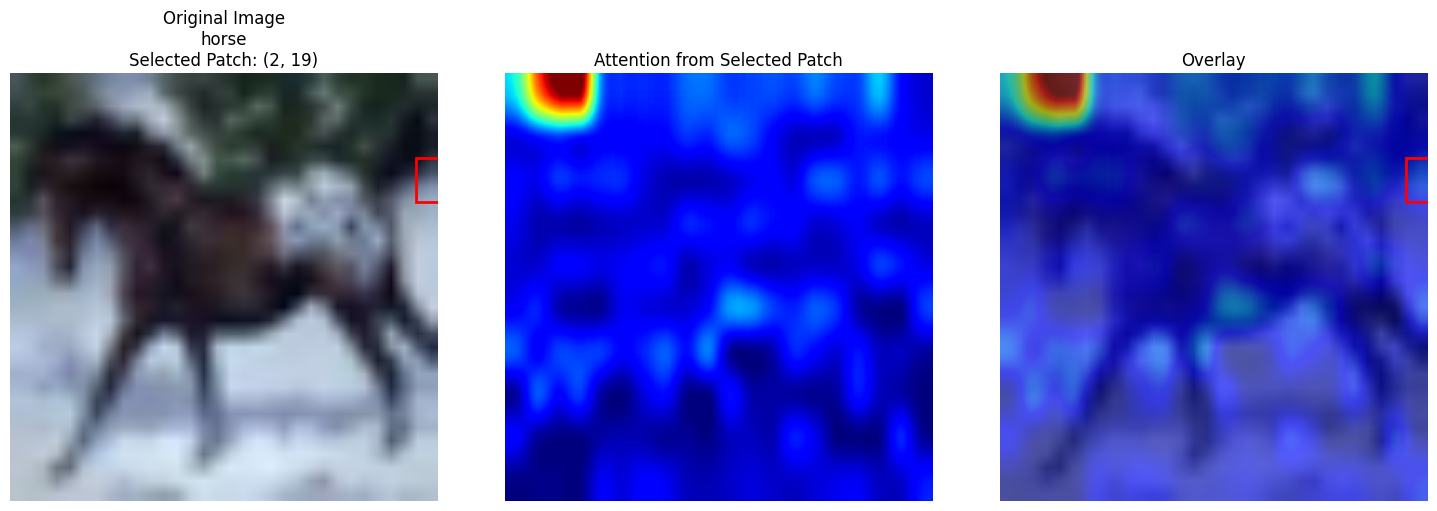

In [119]:
visualize_attention_random(dataset_cifar10, model, processor, device)

Image idx: 7976, Grid: 10x20 = 200, Total patches: 200
Label: telephone
Selected patch: (3, 15) [index: 75]
Attention stats - min: 0.0011, max: 0.0728, mean: 0.0049
Attention map corners:
  Top-left (0,0): 0.0237
  Top-right (0,-1): 0.0045
  Bottom-left (-1,0): 0.0027
  Bottom-right (-1,-1): 0.0063


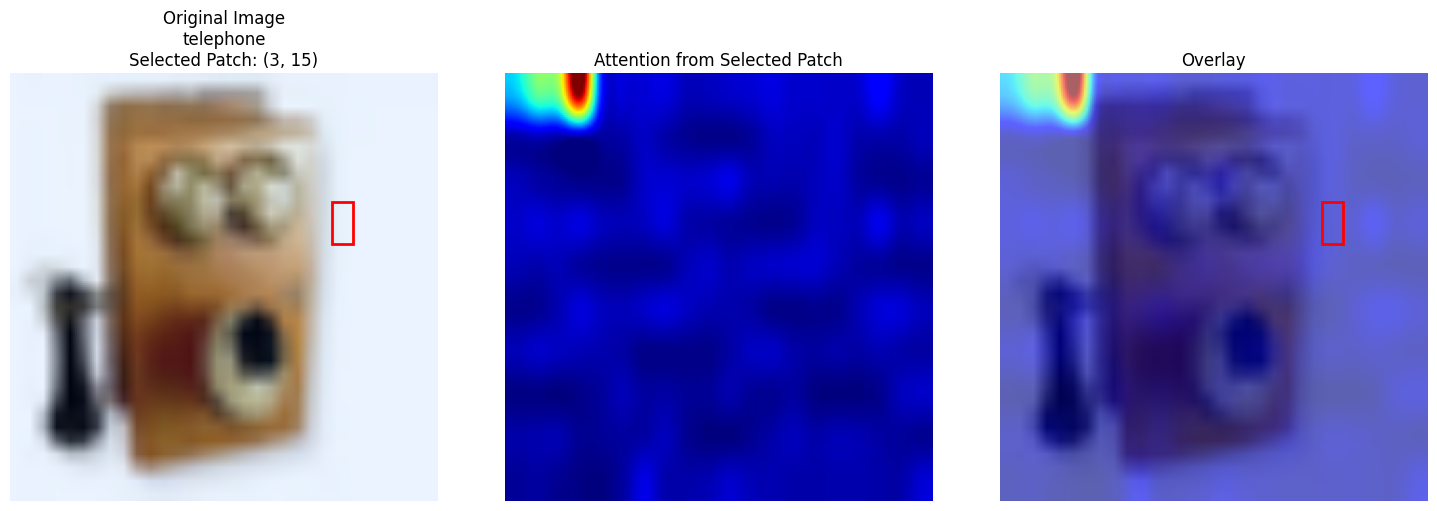

In [120]:
cifar100_class_names = dataset_cifar100.classes if hasattr(dataset_cifar100, 'classes') else [f'class_{i}' for i in range(100)]
visualize_attention_random(dataset_cifar100, model, processor, device, class_names=cifar100_class_names)

### **5.3 Other Datasets**

Image idx: 13115, Grid: 10x20 = 200, Total patches: 200
Label: 8
Selected patch: (1, 1) [index: 21]
Attention stats - min: 0.0007, max: 0.0561, mean: 0.0049
Attention map corners:
  Top-left (0,0): 0.0175
  Top-right (0,-1): 0.0050
  Bottom-left (-1,0): 0.0016
  Bottom-right (-1,-1): 0.0050


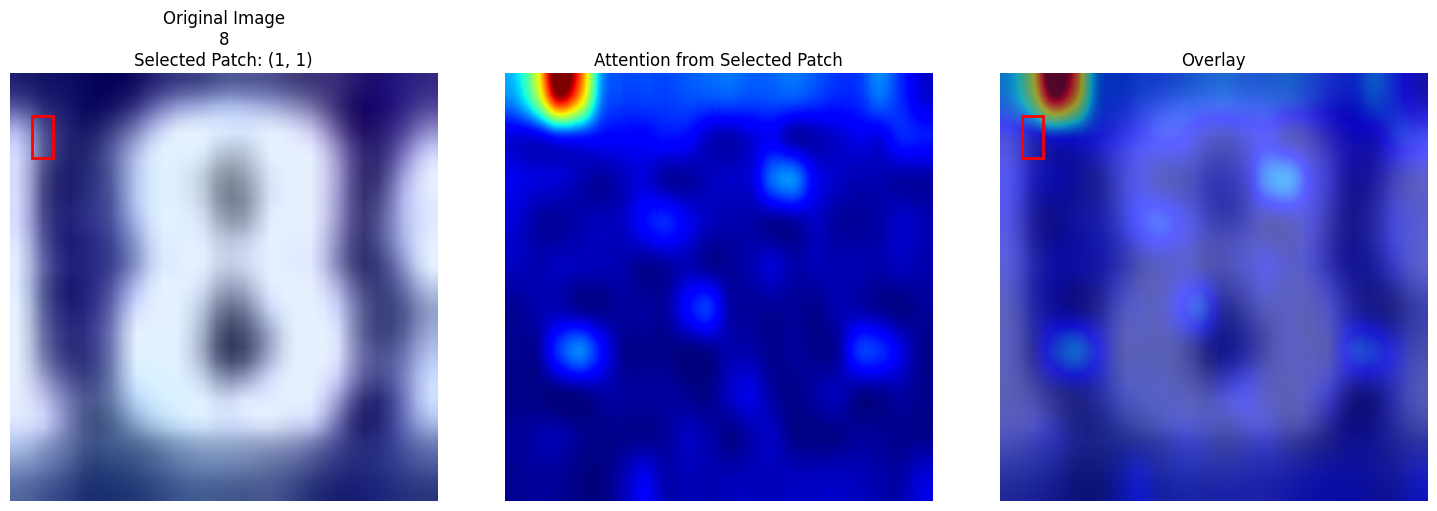

In [121]:
svhn_class_names = [str(i) for i in range(10)]
visualize_attention_random(dataset_svhn, model, processor, device, class_names=svhn_class_names)

Image idx: 11513, Grid: 10x20 = 200, Total patches: 200
Label: red_velvet_cake
Selected patch: (4, 4) [index: 84]
Attention stats - min: 0.0007, max: 0.0155, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0144
  Top-right (0,-1): 0.0007
  Bottom-left (-1,0): 0.0036
  Bottom-right (-1,-1): 0.0039


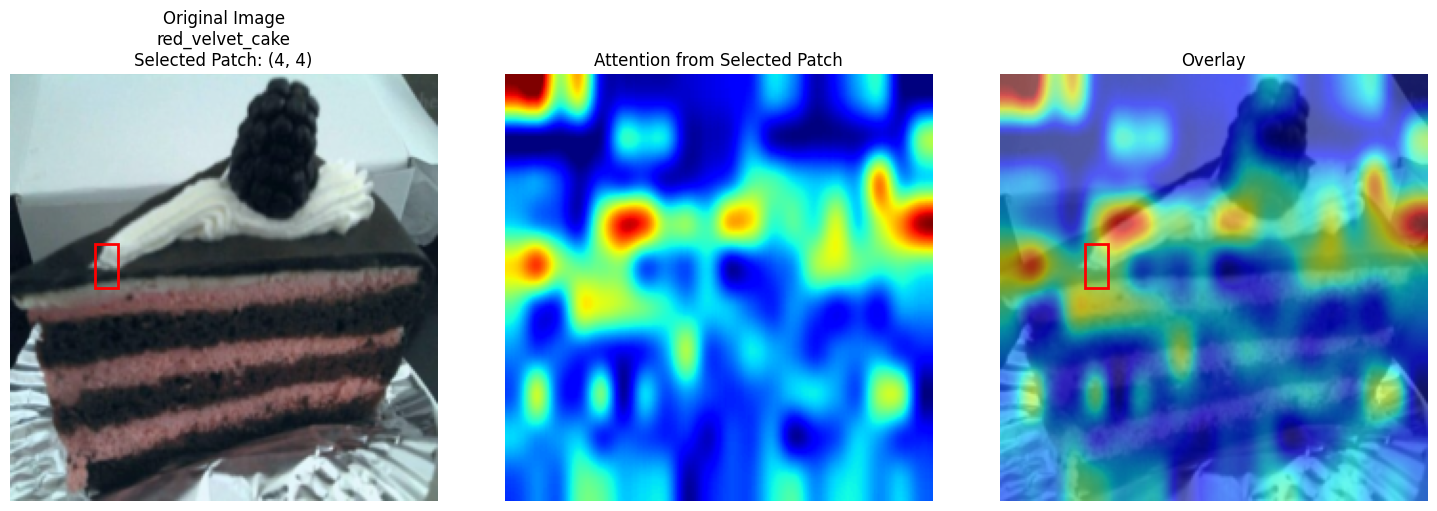

In [122]:
food101_class_names = dataset_food101.classes if hasattr(dataset_food101, 'classes') else [f'food_{i}' for i in range(101)]
visualize_attention_random(dataset_food101, model, processor, device, class_names=food101_class_names)

Image idx: 17060, Grid: 10x20 = 200, Total patches: 200
Label: dataset
Selected patch: (7, 4) [index: 144]
Attention stats - min: 0.0009, max: 0.0320, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0144
  Top-right (0,-1): 0.0054
  Bottom-left (-1,0): 0.0047
  Bottom-right (-1,-1): 0.0049


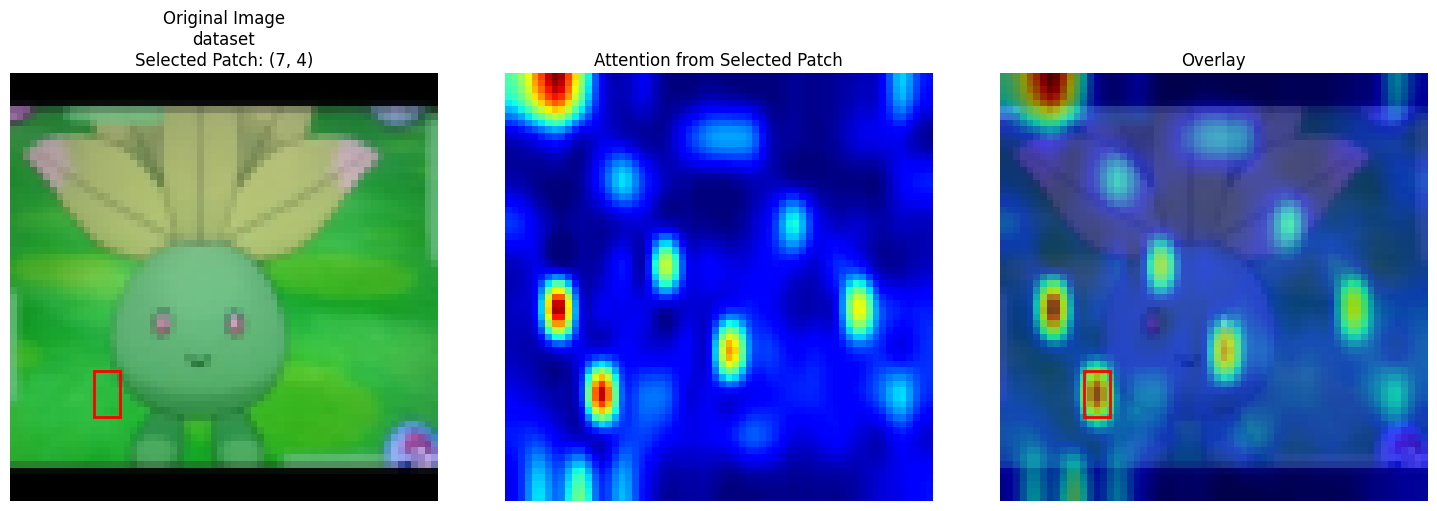

In [123]:
# Pokémon
visualize_attention_random(orig_pokemon_gen1, model, processor, device, class_names=pokemon_class_names)

### **5.4 High-Resolution Images from Internet**

DINO models work much better with higher resolution images (224×224 or larger) compared to low-resolution datasets like CIFAR-10 (32×32). Let's visualize attention on high-quality images downloaded from the internet.

In [124]:
import requests
from io import BytesIO

def download_image_from_url(url, resize=(224, 224)):
    """
    Download an image from a URL and return as PIL Image.

    :param url: URL of the image
    :param resize: Tuple (width, height) to resize the image
    :return: PIL Image
    """
    try:
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        img = Image.open(BytesIO(response.content)).convert('RGB')
        if resize:
            img = img.resize(resize, Image.LANCZOS)
        return img
    except Exception as e:
        print(f"Error downloading image: {e}")
        return None

def visualize_attention_from_url(url, model, processor, device, patch_idx=None, resize=(224, 224)):
    """
    Download an image from URL and visualize attention from a specific patch.

    :param url: URL of the image
    :param model: DINO model
    :param processor: Image processor
    :param device: Device (cuda/cpu)
    :param patch_idx: Index of patch to visualize (if None, selects random)
    :param resize: Size to resize image to
    """
    # Download image
    image = download_image_from_url(url, resize=resize)
    if image is None:
        return

    # Get attention matrix
    attention_matrix = get_attention_maps(image, model, processor, device)

    original_image = np.array(image)
    num_patches_total = attention_matrix.shape[0]
    h, w = original_image.shape[:2]

    # Find valid grid dimensions
    valid_grids = []
    for hp in range(1, num_patches_total + 1):
        if num_patches_total % hp == 0:
            wp = num_patches_total // hp
            valid_grids.append((hp, wp))
    h_patches, w_patches = min(valid_grids, key=lambda x: abs(x[0] - x[1]))

    # Select patch (random or specified)
    if patch_idx is None:
        random_patch_idx = random.randint(0, num_patches_total - 1)
    else:
        random_patch_idx = min(patch_idx, num_patches_total - 1)

    patch_row = random_patch_idx // w_patches
    patch_col = random_patch_idx % w_patches

    # Get attention from this patch
    attention_from_patch = attention_matrix[random_patch_idx, :].cpu().numpy()

    print(f"Image size: {w}×{h}, Grid: {h_patches}×{w_patches} = {h_patches * w_patches}, Total patches: {num_patches_total}")
    print(f"Selected patch: ({patch_row}, {patch_col}) [index: {random_patch_idx}]")
    print(f"Attention stats - min: {attention_from_patch.min():.4f}, max: {attention_from_patch.max():.4f}, mean: {attention_from_patch.mean():.4f}")

    # Reshape attention map
    attention_reshaped = attention_from_patch.reshape(h_patches, w_patches)

    print(f"Attention map corners:")
    print(f"  Top-left (0,0): {attention_reshaped[0, 0]:.4f}")
    print(f"  Top-right (0,-1): {attention_reshaped[0, -1]:.4f}")
    print(f"  Bottom-left (-1,0): {attention_reshaped[-1, 0]:.4f}")
    print(f"  Bottom-right (-1,-1): {attention_reshaped[-1, -1]:.4f}")

    # Normalize attention
    attention_reshaped = (attention_reshaped - attention_reshaped.min()) / \
                         (attention_reshaped.max() - attention_reshaped.min())

    # Upsample to image size
    attention_upsampled = np.array(Image.fromarray((attention_reshaped * 255).astype(np.uint8)).resize((w, h), Image.LANCZOS))
    attention_upsampled = attention_upsampled / 255.0

    # Calculate patch boundaries
    patch_h = h / h_patches
    patch_w = w / w_patches
    patch_y1 = int(patch_row * patch_h)
    patch_y2 = int((patch_row + 1) * patch_h)
    patch_x1 = int(patch_col * patch_w)
    patch_x2 = int((patch_col + 1) * patch_w)

    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Original image with red square
    axes[0].imshow(original_image)
    rect = plt.Rectangle((patch_x1, patch_y1), patch_x2 - patch_x1, patch_y2 - patch_y1,
                         linewidth=3, edgecolor='red', facecolor='none')
    axes[0].add_patch(rect)
    axes[0].set_title(f"Original Image ({w}×{h})\nSelected Patch: ({patch_row}, {patch_col})")
    axes[0].axis("off")

    # Attention heatmap
    axes[1].imshow(attention_upsampled, cmap="jet")
    axes[1].set_title("Attention from Selected Patch")
    axes[1].axis("off")

    # Overlay
    axes[2].imshow(original_image)
    axes[2].imshow(attention_upsampled, cmap="jet", alpha=0.6)
    rect2 = plt.Rectangle((patch_x1, patch_y1), patch_x2 - patch_x1, patch_y2 - patch_y1,
                          linewidth=3, edgecolor='red', facecolor='none')
    axes[2].add_patch(rect2)
    axes[2].set_title("Overlay")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

=== Dog Image ===
Image size: 224×224, Grid: 10×20 = 200, Total patches: 200
Selected patch: (0, 18) [index: 18]
Attention stats - min: 0.0005, max: 0.0640, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0132
  Top-right (0,-1): 0.0430
  Bottom-left (-1,0): 0.0014
  Bottom-right (-1,-1): 0.0020


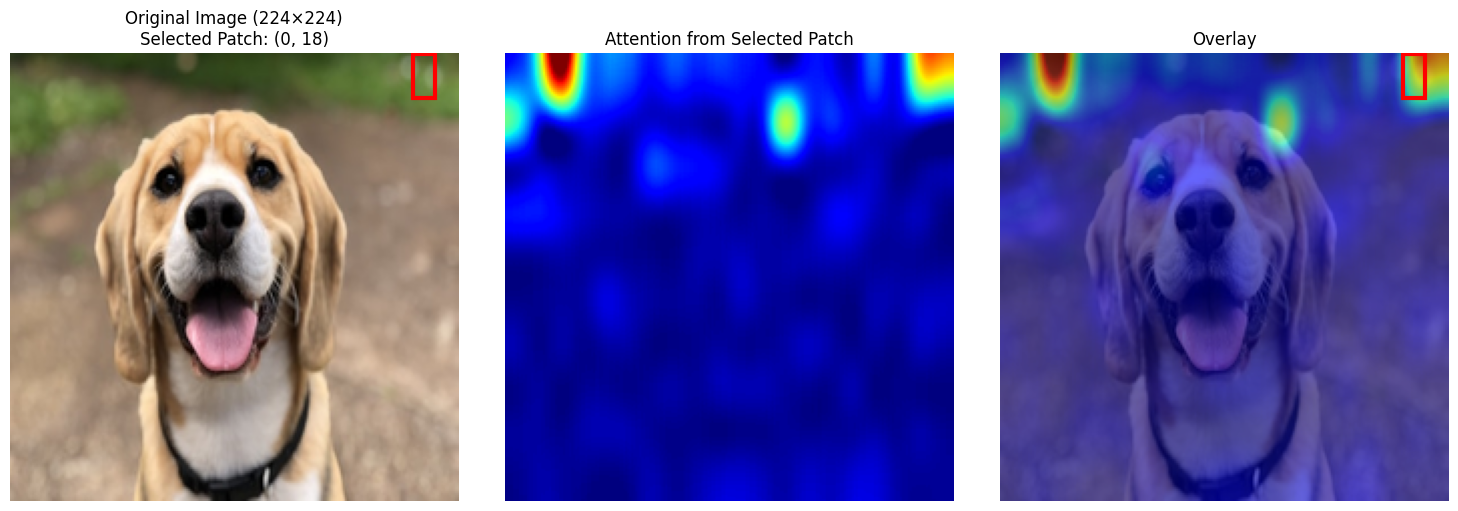

In [125]:
# Example high-resolution images from Unsplash (free to use)

# Dog image
dog_url = "https://images.unsplash.com/photo-1543466835-00a7907e9de1?w=400"
print("=== Dog Image ===")
visualize_attention_from_url(dog_url, model, processor, device, resize=(224, 224))

=== Cat Image ===
Image size: 224×224, Grid: 10×20 = 200, Total patches: 200
Selected patch: (4, 17) [index: 97]
Attention stats - min: 0.0002, max: 0.0776, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0156
  Top-right (0,-1): 0.0003
  Bottom-left (-1,0): 0.0054
  Bottom-right (-1,-1): 0.0008


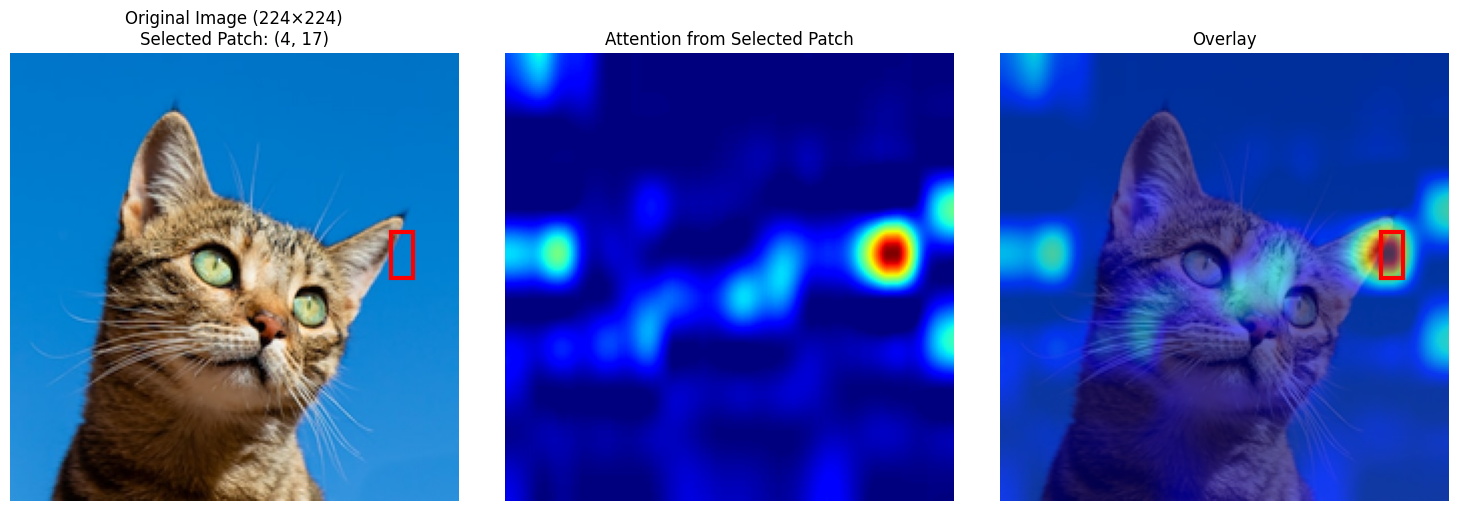

In [126]:
# Cat image
cat_url = "https://images.unsplash.com/photo-1574158622682-e40e69881006?w=400"
print("=== Cat Image ===")
visualize_attention_from_url(cat_url, model, processor, device, resize=(224, 224))

=== Bird Image ===
Image size: 224×224, Grid: 10×20 = 200, Total patches: 200
Selected patch: (2, 15) [index: 55]
Attention stats - min: 0.0001, max: 0.0533, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0127
  Top-right (0,-1): 0.0005
  Bottom-left (-1,0): 0.0005
  Bottom-right (-1,-1): 0.0010


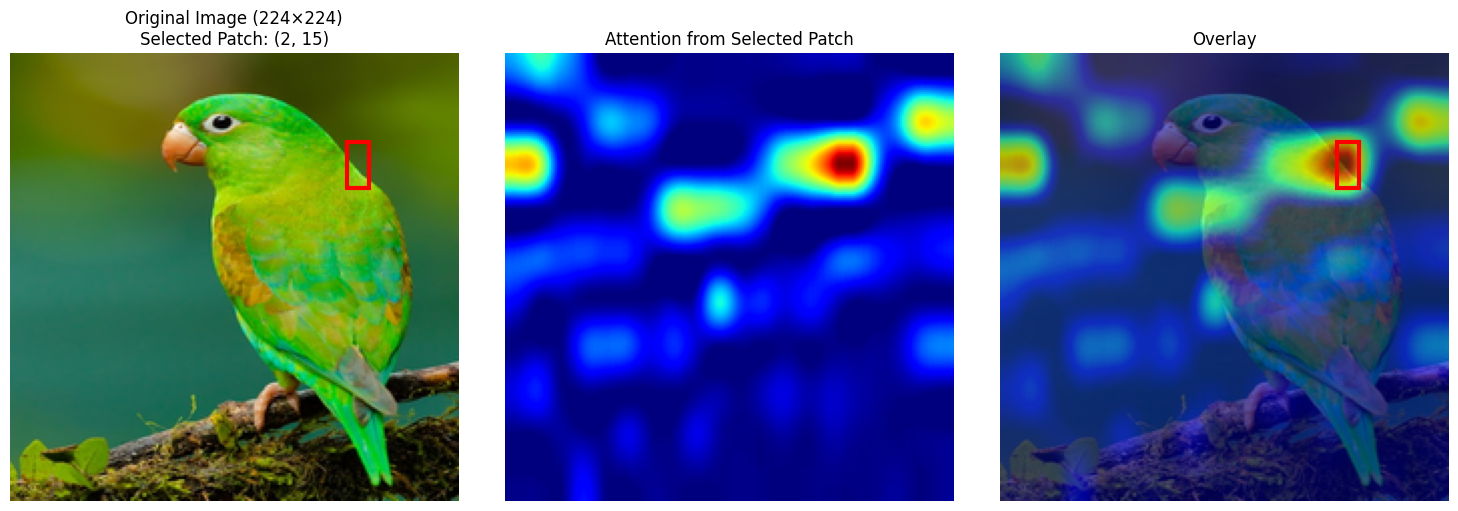

In [127]:
# Bird image
bird_url = "https://images.unsplash.com/photo-1552728089-57bdde30beb3?w=400"
print("=== Bird Image ===")
visualize_attention_from_url(bird_url, model, processor, device, resize=(224, 224))

=== Landscape Image ===
Image size: 224×224, Grid: 10×20 = 200, Total patches: 200
Selected patch: (9, 15) [index: 195]
Attention stats - min: 0.0003, max: 0.0368, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0081
  Top-right (0,-1): 0.0007
  Bottom-left (-1,0): 0.0111
  Bottom-right (-1,-1): 0.0368


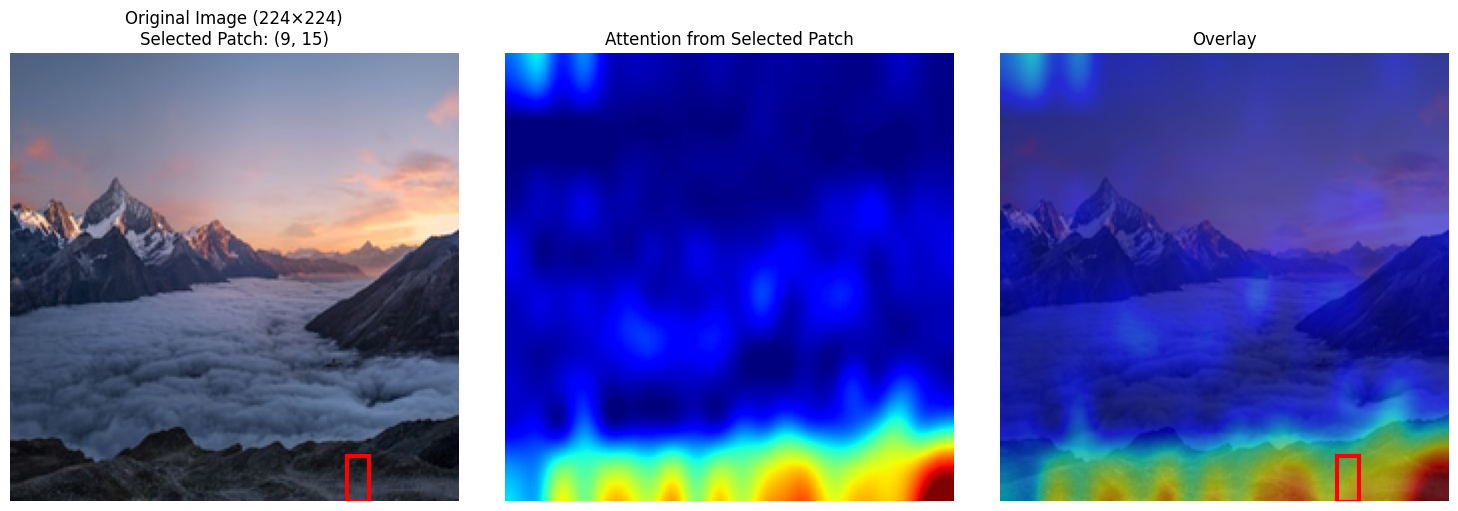

In [128]:
# Landscape image
landscape_url = "https://images.unsplash.com/photo-1506905925346-21bda4d32df4?w=400"
print("=== Landscape Image ===")
visualize_attention_from_url(landscape_url, model, processor, device, resize=(224, 224))

=== Street Scene ===
Image size: 224×224, Grid: 10×20 = 200, Total patches: 200
Selected patch: (7, 11) [index: 151]
Attention stats - min: 0.0003, max: 0.0481, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0187
  Top-right (0,-1): 0.0012
  Bottom-left (-1,0): 0.0079
  Bottom-right (-1,-1): 0.0072


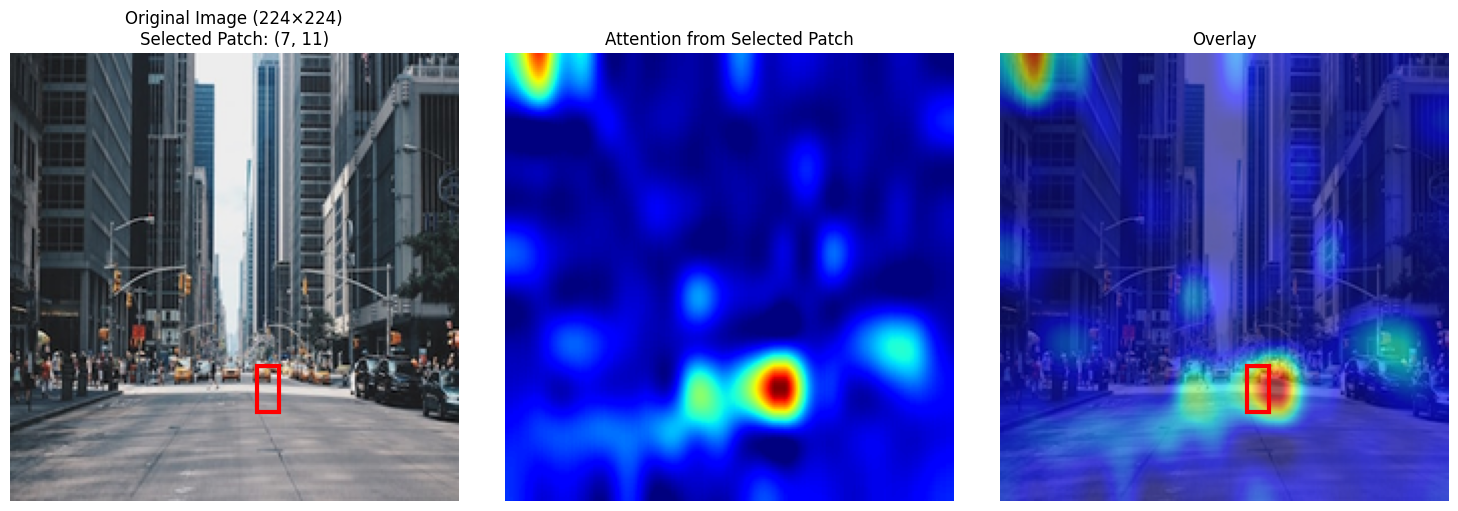

In [136]:
# Street scene
street_url = "https://images.unsplash.com/photo-1449824913935-59a10b8d2000?w=400"
print("=== Street Scene ===")
visualize_attention_from_url(street_url, model, processor, device, resize=(224, 224))

### **5.5 Custom URL**

You can also try your own images by providing a URL:

Image size: 224×224, Grid: 10×20 = 200, Total patches: 200
Selected patch: (3, 18) [index: 78]
Attention stats - min: 0.0001, max: 0.0684, mean: 0.0050
Attention map corners:
  Top-left (0,0): 0.0473
  Top-right (0,-1): 0.0006
  Bottom-left (-1,0): 0.0005
  Bottom-right (-1,-1): 0.0016


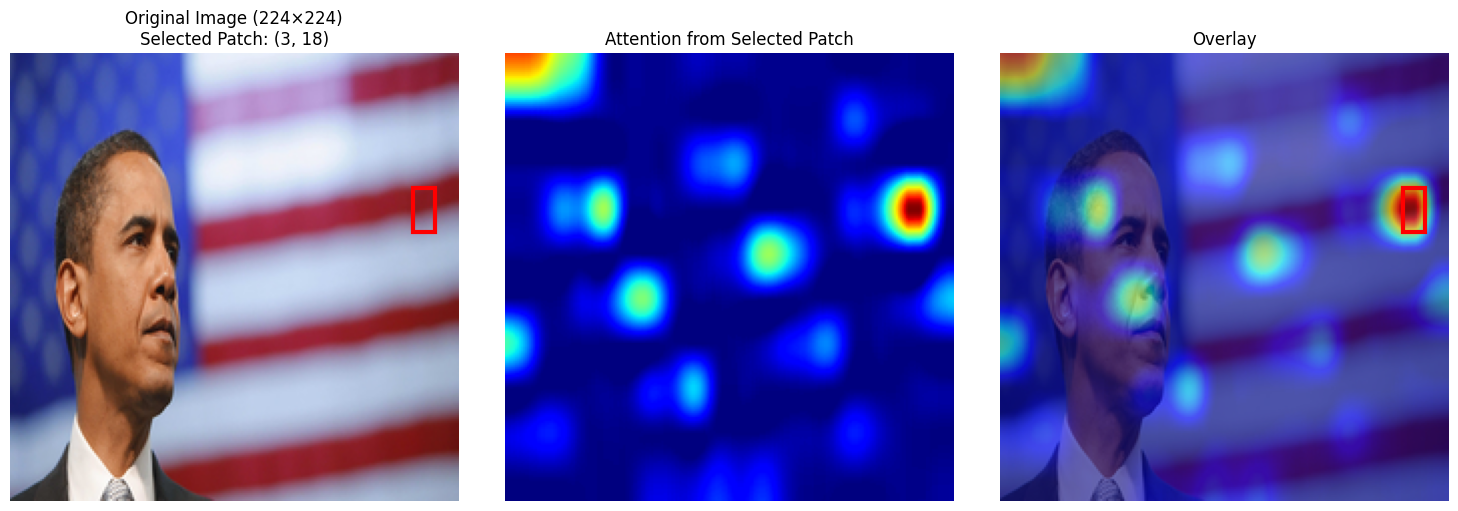

In [134]:
custom_url = "https://res.cloudinary.com/aenetworks/image/upload/c_fill,ar_2,w_3840,h_1920,g_auto/dpr_auto/f_auto/q_auto:eco/v1/gettyimages-81389308?_a=BAVAZGID0"
# Uncomment to run:
visualize_attention_from_url(custom_url, model, processor, device, resize=(224, 224))
